# Fashion-MNIST classification with a Simplex LDA head and SIGRegNLL

Companion to `FashionMNIST.ipynb`: use its convolutional encoder,
nine-dimensional embeddings, LDA head with its default fixed covariance
$\Sigma=I/D=I_9/9$ ($\sigma=1/3$), and 100-epoch
Adam training. Train on **all 60,000 Fashion-MNIST training examples** and
evaluate on the separate 10,000-example test set. Replace generative NLL with
**SIGRegNLL**, adding class-wise Gaussianity regularization from
[LeJEPA.pdf](LeJEPA.pdf), Section 4.2.3 and Algorithm 1, as in
`Synthetic_SIGReg.ipynb`.

Report predictive NLL/ECE and accuracy, visualize PCA embeddings, and plot
confidence and reliability from the model's original predictions. Figures use
`sigregnll` filenames under `plots/`.

Run all cells in order from `simplex-lda/` or its parent `LDA/`. Requires PyTorch,
torchvision, NumPy, and Matplotlib. The first run may download Fashion-MNIST.
Set `SIGREG_WEIGHT` in setup; zero recovers generative NLL with the same fixed covariance.


### Setup


In [1]:
from pathlib import Path
import sys

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Support kernels started in simplex-lda/ or its parent LDA/ directory.
project_dir = Path.cwd()
if not (project_dir / 'lda.py').is_file():
    project_dir = project_dir / 'simplex-lda'
if not (project_dir / 'lda.py').is_file():
    raise RuntimeError('Start the kernel in simplex-lda/ or its parent LDA/ directory.')
project_dir = project_dir.resolve()
sys.path.insert(0, str(project_dir))
from lda import SimplexLDAHead
from sigreg import SIGRegNLLLoss

EPOCHS = 100
BATCH_SIZE = 256
EVAL_BATCH_SIZE = 1024
NUM_WORKERS = 2  # Set to 0 if multiprocessing is unavailable.
SIGREG_WEIGHT = 1.0
SIGREG_NUM_SLICES = 256
SIGREG_SEED = 1729

plot_dir = project_dir / 'plots'
plot_dir.mkdir(parents=True, exist_ok=True)


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pin_memory = device.type == 'cuda'
print('device =', device)


device = cuda


### Data


In [3]:
tfm = transforms.ToTensor()
train_ds = datasets.FashionMNIST(root=str(project_dir / 'data'), train=True, transform=tfm, download=True)
test_ds = datasets.FashionMNIST(root=str(project_dir / 'data'), train=False, transform=tfm, download=True)
# Use the entire official training set; the test set is for reporting only.
train_ld = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_ld = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory)
len(train_ds), len(test_ds)


(60000, 10000)

### Model: encoder + LDA head with fixed spherical covariance


In [4]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(256, dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.proj(x)

class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D)  # Default fixed covariance I / D.
    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)


### Train with SIGRegNLL and evaluate

Use `SIGRegNLLLoss` from `sigreg.py`:
\[
\mathcal L= -\frac{1}{N}\sum_i s_{y_i}(z_i)
 + \lambda_G\sum_c\frac{n_c}{N}\mathrm{EP}_c,\qquad
s_c(z)=\log\pi_c-\tfrac12\left(\|z-\mu_c\|^2/\sigma^2+9\log\sigma^2\right).
\]
The generative NLL uses unnormalized LDA log scores, without `log_softmax`.
For each class separately, SIGReg compares the characteristic functions of
projected standardized residuals $(z_i-\mu_c)/\sigma$ against $N(0,1)$,
targeting $N(\mu_c,\sigma^2 I_9)$. Residuals use the **fixed simplex center**
and the **fixed shared standard deviation**, without empirical centering or
sample covariance estimation. Both NLL and SIGReg use the same fixed scale
$\sigma=1/\sqrt{D}=1/3$, so each class targets $N(\mu_c,I_9/9)$.

Following LeJEPA Algorithm 1, use 256 random unit projections, 17 integration
points on $[-5,5]$, and the Gaussian integration window. Increment `step` across
minibatches to resample projections with a private generator. Retain each class
statistic's $n_c$ multiplier and weight classes by $n_c/N$. Absent classes and
singletons contribute zero, without renormalizing the other weights.

Adam optimizes **only the encoder**. Calling `SimplexLDAHead(C, D)` without
an override gives fixed covariance $\Sigma=I/D$; with $D=9$, the variance is
$1/9$ and standard deviation is $1/3$. There are no covariance parameters.
SIGReg reads the variance from `head.cov_diag`, keeping its target aligned with
the head. Class means are fixed, and priors remain at their uniform initialization. Train on all 60,000 training examples with the 100-epoch default.
`SIGREG_WEIGHT=1.0` is a starting setting, not a tuned Fashion-MNIST result.
The penalty's strength depends on batch size because of the $n_c$ multiplier.
Finite regularization encourages Gaussianity rather than guaranteeing it.
Test accuracy reports progress; it does not select epochs or weights.


In [5]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ok = tot = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)  # fixed shared spherical covariance
        ok += (logits.argmax(1) == y).sum().item()
        tot += y.size(0)
    return ok / tot

model = DeepLDA(C=10, D=9).to(device)
variance = model.head.cov_diag[0]
log_variance = variance.log()
# Keep covariance and uniform class priors fixed; train only the encoder.
model.head.prior_logits.requires_grad_(False)
opt = torch.optim.Adam(model.encoder.parameters())
loss_fn = SIGRegNLLLoss(
    gaussianity_weight=SIGREG_WEIGHT,
    num_slices=SIGREG_NUM_SLICES,
    seed=SIGREG_SEED,
).to(device)
step = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum = acc_sum = n_sum = 0
    for x, y in train_ld:
        x, y = x.to(device), y.to(device)
        embeddings = model.encoder(x)
        logits = model.head(embeddings)
        loss = loss_fn(
            logits, y, embeddings, model.head.mu,
            step=step, log_variance=log_variance,
        )
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite SIGRegNLL loss at epoch {epoch}, step {step}')
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        step += 1
        with torch.no_grad():
            pred = logits.argmax(1)
            acc_sum += (pred == y).sum().item()
            n_sum += y.size(0)
            loss_sum += loss.item() * y.size(0)
    tr_acc = acc_sum / n_sum
    te_acc = evaluate(model, test_ld)
    print(
        f"[{epoch:02d}] train loss={loss_sum/n_sum:.4f} "
        f"acc={tr_acc:.4f} | test acc={te_acc:.4f} "
        f"| variance={variance.item():.4f}"
    )


[01] train loss=26.5515 acc=0.8195 | test acc=0.8663 | variance=0.1111
[02] train loss=13.1874 acc=0.9001 | test acc=0.8787 | variance=0.1111
[03] train loss=10.2646 acc=0.9189 | test acc=0.9122 | variance=0.1111
[04] train loss=8.6185 acc=0.9282 | test acc=0.8987 | variance=0.1111
[05] train loss=7.4441 acc=0.9356 | test acc=0.9083 | variance=0.1111
[06] train loss=6.4977 acc=0.9412 | test acc=0.9085 | variance=0.1111
[07] train loss=5.7627 acc=0.9477 | test acc=0.9261 | variance=0.1111
[08] train loss=5.2939 acc=0.9517 | test acc=0.9184 | variance=0.1111
[09] train loss=4.4134 acc=0.9564 | test acc=0.9244 | variance=0.1111
[10] train loss=3.8361 acc=0.9626 | test acc=0.9222 | variance=0.1111
[11] train loss=3.2497 acc=0.9671 | test acc=0.9221 | variance=0.1111
[12] train loss=2.7516 acc=0.9708 | test acc=0.9270 | variance=0.1111
[13] train loss=2.2259 acc=0.9757 | test acc=0.9265 | variance=0.1111
[14] train loss=1.8333 acc=0.9787 | test acc=0.9160 | variance=0.1111
[15] train loss=1

### Test prediction metrics

Compute predictive NLL, ECE, and accuracy directly from the model's test scores.
Predictive NLL uses cross-entropy; it is distinct from the generative SIGRegNLL
training objective. Test examples are used only for reporting.


In [6]:
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        logits.append(model(x.to(device)).detach().cpu())
        labels.append(y.cpu())
    return torch.cat(logits), torch.cat(labels)


In [7]:
@torch.no_grad()
def prediction_metrics(logits, labels, n_bins=15):
    confidence, predictions = logits.softmax(dim=1).max(dim=1)
    correct = predictions.eq(labels).float()
    # Equal-width bins, including confidence 0 and 1.
    bin_ids = (confidence * n_bins).long().clamp(max=n_bins - 1)
    ece = confidence.new_zeros(())
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.float().mean() * (
                confidence[mask].mean() - correct[mask].mean()
            ).abs()
    return {
        'NLL': F.cross_entropy(logits, labels).item(),
        'ECE': ece.item(),
        'accuracy': correct.mean().item(),
    }


test_logits, test_labels = collect_logits(model, test_ld)
metrics = prediction_metrics(test_logits, test_labels)
print(f"{'Test predictions':<20} {'NLL':>9} {'ECE':>9} {'Accuracy':>9}")
print(f"{'Original':<20} {metrics['NLL']:9.4f} {metrics['ECE']:9.4f} {metrics['accuracy']:9.4f}")


Test predictions           NLL       ECE  Accuracy
Original                4.9163    0.0724    0.9265


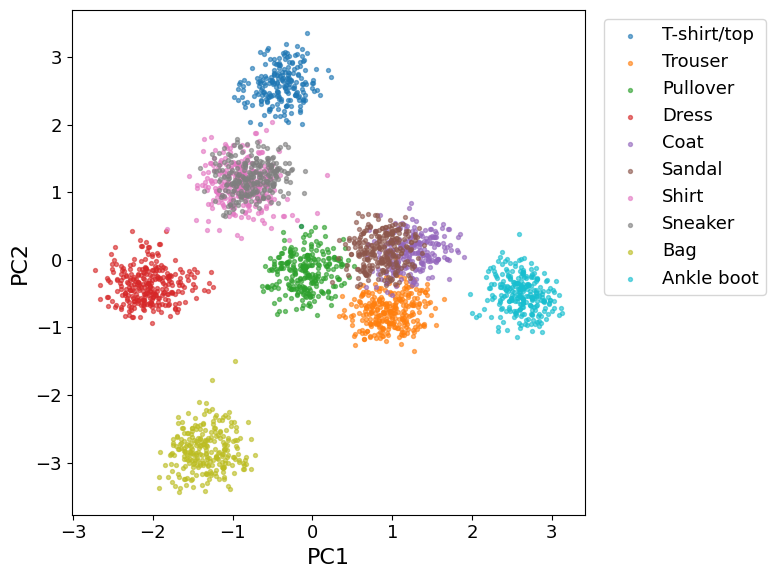

In [8]:
import matplotlib.pyplot as plt

model.eval()
embeds, labels = [], []
with torch.no_grad():
    for i, (x, y) in enumerate(train_ld):   # Training embeddings, as in the reference.
        x = x.to(device)
        z = model.encoder(x).cpu()
        embeds.append(z)
        labels.append(y)
        if i >= 9:   # 10 batches ≈2,560 points at batch size 256.
            break

z = torch.cat(embeds)
y = torch.cat(labels)

# 2D projection (PCA)
z0 = z - z.mean(0, keepdim=True)
U, S, V = torch.pca_lowrank(z0, q=2)
z2 = z0 @ V[:, :2]

plt.rcParams.update({
    "font.size": 14, "axes.labelsize": 16, "legend.fontsize": 13,
    "xtick.labelsize": 13, "ytick.labelsize": 13
})

plt.figure(figsize=(8, 6))
for c in range(10):
    idx = y == c
    plt.scatter(z2[idx, 0], z2[idx, 1], s=8, alpha=0.6, label=train_ds.classes[c])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout()
plt.savefig(plot_dir / 'fmnist_sigregnll_embeddings.png', dpi=600)


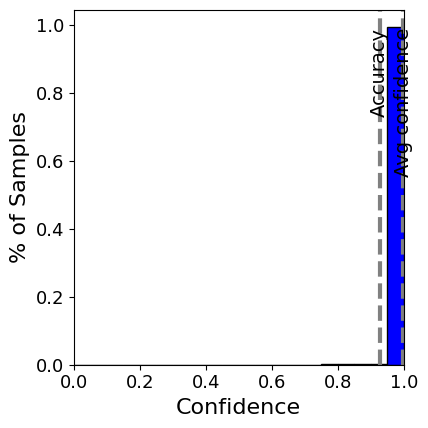

In [9]:
import numpy as np
import matplotlib.pyplot as plt

model.eval()
conf_list = []
pred_list = []
label_list = []

with torch.no_grad():
    for x, y in test_ld:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        probs = F.softmax(logits, dim=1)
        conf, pred = probs.max(1)
        conf_list.append(conf.cpu())
        pred_list.append(pred.cpu())
        label_list.append(y.cpu())

conf = torch.cat(conf_list).numpy()
pred = torch.cat(pred_list).numpy()
labels = torch.cat(label_list).numpy()
acc = (pred == labels).mean()
avg_conf = conf.mean().item()

bins = np.linspace(0.0, 1.0, 21)
weights = np.ones_like(conf) / conf.size

plt.figure(figsize=(4.5, 4.5))
plt.hist(conf, bins=bins, weights=weights, color='blue', edgecolor='black')
plt.axvline(avg_conf, color='gray', linestyle='--', linewidth=3)
plt.axvline(acc, color='gray', linestyle='--', linewidth=3)
plt.text(avg_conf, 0.95 * plt.gca().get_ylim()[1], 'Avg confidence',
         rotation=90, va='top', ha='center')
plt.text(acc, 0.95 * plt.gca().get_ylim()[1], 'Accuracy',
         rotation=90, va='top', ha='center')
plt.xlabel('Confidence')
plt.ylabel('% of Samples')
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(plot_dir / 'fashionmnist_sigregnll_confidence_hist.png', dpi=600)

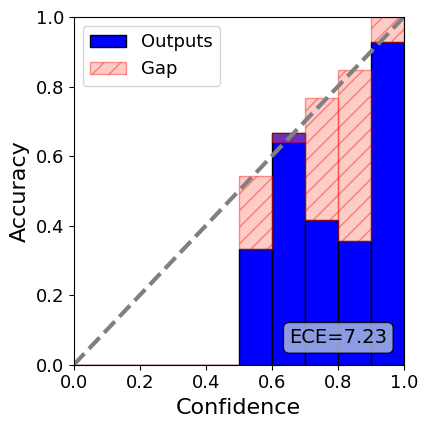

In [10]:
import numpy as np
import matplotlib.pyplot as plt

model.eval()
conf_list = []
pred_list = []
label_list = []
with torch.no_grad():
    for x, y in test_ld:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        probs = F.softmax(logits, dim=1)
        conf, pred = probs.max(1)
        conf_list.append(conf.cpu())
        pred_list.append(pred.cpu())
        label_list.append(y.cpu())

conf = torch.cat(conf_list).numpy()
pred = torch.cat(pred_list).numpy()
labels = torch.cat(label_list).numpy()
correct = (pred == labels).astype(np.float32)

n_bins = 10
bins = np.linspace(0.0, 1.0, n_bins + 1)
bin_ids = np.digitize(conf, bins[1:-1], right=True)

bin_acc = np.zeros(n_bins, dtype=np.float32)
bin_conf = np.zeros(n_bins, dtype=np.float32)
bin_frac = np.zeros(n_bins, dtype=np.float32)

for b in range(n_bins):
    mask = bin_ids == b
    if mask.any():
        bin_acc[b] = correct[mask].mean()
        bin_conf[b] = conf[mask].mean()
        bin_frac[b] = mask.mean()

ece = np.sum(np.abs(bin_acc - bin_conf) * bin_frac)

bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=3)
plt.bar(bin_centers, bin_acc, width=bin_width, color='blue', edgecolor='black', label='Outputs')
gap = bin_conf - bin_acc
plt.bar(bin_centers, gap, bottom=bin_acc, width=bin_width, color='salmon', edgecolor='red',
        alpha=0.4, hatch='//', label='Gap')
plt.xlabel('Confidence')
plt.ylabel('Accuracy')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.text(0.95, 0.05, f'ECE={ece*100:.2f}', ha='right', va='bottom',
         bbox=dict(boxstyle='round', facecolor='lightsteelblue', alpha=0.8))
plt.tight_layout()
plt.savefig(plot_dir / 'fashionmnist_sigregnll_reliability_diagram.png', dpi=600)
